In [1]:
import spacy
from spacy.cli import download
import pandas as pd 
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [2]:
# Cargar modelo en español
try:
    nlp = spacy.load("es_core_news_sm")
except OSError:
    print("Descargando modelo...")
    download("es_core_news_sm")
    nlp = spacy.load("es_core_news_sm")

# Texto de entrada:
with open ("./pinochoCap1.txt", "r", encoding="utf-8") as f:
    texto_pinocho = f.read()

# Longitud del texto del archivo
print(f"Texto cargado con exito. Longitud: {len(texto_pinocho)} caracteres")

# 1. TOKENIZACIÓN
# SpaCy procesa el texto y crea el objeto 'doc'
doc = nlp(texto_pinocho)

# Mostrar los primeros 15 tokens
print(f"--- 1. Tokenización (Total tokens: {len(doc)} ---)")
print([token.text for token in doc][:20])

Texto cargado con exito. Longitud: 4454 caracteres
--- 1. Tokenización (Total tokens: 1045 ---)
['Escuchen', ',', 'mis', 'pequeños', 'lectores', '.', '\n', 'Había', 'una', 'vez', 'un', 'pedazo', 'de', 'madera', '.', 'Un', 'simple', 'trozo', '\n', 'de']


In [5]:
# 2 FILTRADO DE STOP WORDS

tokens_relevantes = []
tokens_ruido =[]

for token in doc:
    if not token.is_stop and not token.is_punct and token.text.strip():
        tokens_relevantes.append(token.text)
    elif token.is_stop:
        tokens_ruido.append(token.text)

print(f"\n --- Filtrado de Stop Words ---")
print(f"Palabras eliminadas (ruido): {tokens_ruido[:10]}...")
print(f"Palabras conservadas (contenido): {tokens_relevantes[:10]}")
print(f"Reducción de tamaño de {len(doc)} a {len(tokens_relevantes)} tokens.")


 --- Filtrado de Stop Words ---
Palabras eliminadas (ruido): ['mis', 'Había', 'una', 'vez', 'un', 'de', 'Un', 'de', 'de', 'esos']...
Palabras conservadas (contenido): ['Escuchen', 'pequeños', 'lectores', 'pedazo', 'madera', 'simple', 'trozo', 'leña', 'invierno', 'encienden']
Reducción de tamaño de 1045 a 336 tokens.


In [10]:
# 3. LEMATIZACIÓN Y NORMALIZACIÓN
# Reducir las palabras a su raíz (lematizaciión) y estandarizar minúsculas
# Objetivo: Que "hablo" "hablare" y "habla" -> "hablar"

tokens_normalizados = []

for token in doc:
    if not token.is_stop and not token.is_punct and token.text.strip():

        lema = token.lemma_.lower()
        tokens_normalizados.append(lema)

print(f"\n--- 3. Normalización y Lematización ---")
print(f"Total de tokens procesados: {len(tokens_normalizados)}")
print(f"\nResultado final (Primeros 10 tokens):")
print(tokens_normalizados[:20])



--- 3. Normalización y Lematización ---
Total de tokens procesados: 336

Resultado final (Primeros 10 tokens):
['escuchen', 'pequeño', 'lector', 'pedazo', 'madera', 'simple', 'trozo', 'leña', 'invierno', 'encender', 'estufa', 'chimenea', 'calentar', 'habitación', 'niño', 'caso', 'trozo', 'leña', 'cuento', 'parar']


In [14]:
# 4. VECTORIZACIÓN

corpus_lematizado = []
for oracion in doc.sents:
    lemas_oracion = [
        token.lemma_.lower()
        for token in oracion
        if not token.is_punct and not token.is_space and not token.is_stop
    ]
    if lemas_oracion:
        corpus_lematizado.append(" ".join(lemas_oracion))

print(f"Total de oraciones procesadas: {len(corpus_lematizado)}")
print(f"\nPrimeras 3 oraciones: \n{corpus_lematizado[:3]}")

Total de oraciones procesadas: 45

Primeras 3 oraciones: 
['escuchen pequeño lector', 'pedazo madera', 'simple trozo leña invierno encender estufa chimenea calentar habitación']


In [15]:
# Para TF-IDF
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(corpus_lematizado)

In [16]:
# Para Bag of Words
bow_vetorizer = CountVectorizer()
X_bow = bow_vetorizer.fit_transform(corpus_lematizado)

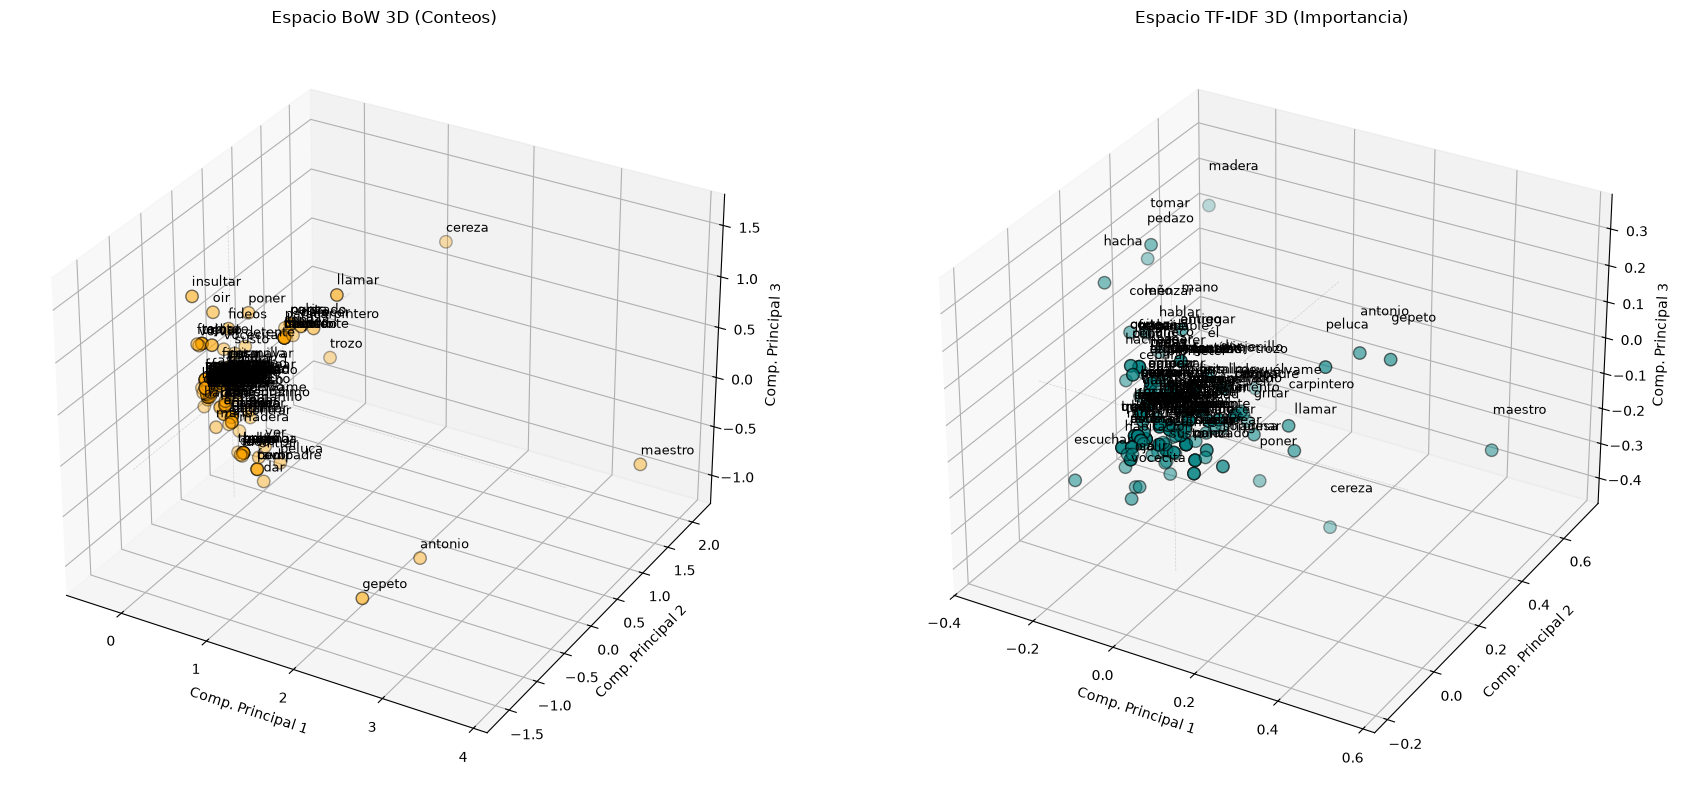

In [18]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D # Import necesario para 3D
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np

# ---------------------------------------------------------
# FUNCIÓN AUXILIAR PARA GRAFICAR EN 3D
# ---------------------------------------------------------
def graficar_palabras_3d(ax, matriz, vocabulario, titulo, color_puntos):
    # 1. TRANSPONER: Filas = Palabras, Columnas = Contextos
    matriz_palabras = matriz.T

    # 2. PCA: Reducir a 3 DIMENSIONES
    pca = PCA(n_components=3)
    coords = pca.fit_transform(matriz_palabras.toarray())

    # Extraer coordenadas X, Y, Z
    x = coords[:, 0]
    y = coords[:, 1]
    z = coords[:, 2]

    # 3. GRAFICAR SCATTER 3D
    # Usamos profundidad visual (depthshade=True) para ayudar a la perspectiva
    ax.scatter(x, y, z, c=color_puntos, s=80, edgecolors='k', alpha=0.8, depthshade=True)

    # Etiquetar puntos
    for i, palabra in enumerate(vocabulario):
        # Agregamos un pequeño offset a Z para que el texto flote sobre el punto
        ax.text(x[i], y[i], z[i] + 0.1, palabra, fontsize=9)

    ax.set_title(titulo)
    ax.set_xlabel('Comp. Principal 1')
    ax.set_ylabel('Comp. Principal 2')
    ax.set_zlabel('Comp. Principal 3')

    # Líneas de referencia en el origen (0,0,0)
    ax.plot([0,0], [0,0], [z.min(), z.max()], c='grey', ls='--', lw=0.5, alpha=0.3)
    ax.plot([x.min(), x.max()], [0,0], [0,0], c='grey', ls='--', lw=0.5, alpha=0.3)
    ax.plot([0,0], [y.min(), y.max()], [0,0], c='grey', ls='--', lw=0.5, alpha=0.3)


# ---------------------------------------------------------
# CONFIGURACIÓN DE LA FIGURA 3D
# ---------------------------------------------------------
# Creamos una figura ancha para poner dos gráficos lado a lado
fig = plt.figure(figsize=(18, 8))

# --- A. BAG OF WORDS (Izquierda) ---
# subplot(filas, columnas, índice, proyección)
ax1 = fig.add_subplot(121, projection='3d')

bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit_transform(corpus_lematizado)
vocab_bow = bow_vectorizer.get_feature_names_out()

graficar_palabras_3d(ax1, X_bow, vocab_bow,
                     "Espacio BoW 3D (Conteos)",
                     "orange")

# --- B. TF-IDF (Derecha) ---
ax2 = fig.add_subplot(122, projection='3d')

tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(corpus_lematizado)
vocab_tfidf = tfidf_vectorizer.get_feature_names_out()

graficar_palabras_3d(ax2, X_tfidf, vocab_tfidf,
                     "Espacio TF-IDF 3D (Importancia)",
                     "teal")

plt.tight_layout()
plt.show()